# 第 50 课｜scikit-learn 防泄漏时序分类

本 Notebook 对应「365 天量化金融」第 50 课。课程方法来自本地完整视频、课件截图和本地 Whisper 口播整理；这里把它重建为默认离线、可核对、可重复执行的量化教学实现。

- 图文口播：`/Users/mojiawen/Documents/学习资料归档/_暂存/pam-video-captures/365-days-quant-finance/50_youtube-iBTEouhPvC4/index.html`
- 环境：`pkm-quant`
- 数据：离线模拟日线；用于时间序列机器学习方法验证
- 状态：可运行学习稿；不代表策略收益承诺

> 网络接口和研究计算分离：Notebook 默认不请求第三方服务。真实接口只作为适配层示意，计算使用带来源声明的本地快照，避免限流、字段变化和历史数据重算破坏复现。

## 本节量化问题

预测明日涨跌时，特征只能使用 t 日及以前信息，标签是 `y_t = 1[r_{t+1}>0]`。预处理必须只在训练折拟合，验证必须保持时间顺序，最终策略收益还要把信号延迟和成本纳入。

In [1]:
from pathlib import Path
import json
import os
import platform
import sys
import tempfile
import timeit

# Matplotlib 首次运行需要写字体缓存；放到可写临时目录，避免污染用户目录。
MPL_CACHE_DIR = Path(tempfile.gettempdir()) / "pkm-quant-matplotlib"
MPL_CACHE_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(MPL_CACHE_DIR))

import matplotlib.pyplot as plt
from matplotlib import font_manager
import numpy as np
import pandas as pd
import seaborn as sns

# 从本机字体中选择支持中文的字体，避免标题显示成方框。
preferred_chinese_fonts = [
    "PingFang SC",
    "Arial Unicode MS",
    "Hiragino Sans GB",
    "Heiti SC",
]
available_font_names = {font.name for font in font_manager.fontManager.ttflist}
chinese_font = next(
    (name for name in preferred_chinese_fonts if name in available_font_names),
    "DejaVu Sans",
)
plt.rcParams["font.sans-serif"] = [chinese_font, "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

def find_project_root():
    cwd = Path.cwd().resolve()
    candidates = [
        cwd,
        cwd / "实验" / "p2-python-toolchain",
        cwd / "p2-python-toolchain",
        *cwd.parents,
    ]
    for candidate in candidates:
        if (candidate / "课程辅助设计.md").exists():
            return candidate
    raise FileNotFoundError("请从 p2-python-toolchain 或量化交易项目目录启动 JupyterLab")

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data" / "fixtures"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
RANDOM_SEED = 365

print("Python:", sys.version.split()[0])
print("解释器:", sys.executable)
print("项目:", PROJECT_ROOT)
print("绘图字体:", chinese_font)

Python: 3.11.15
解释器: /opt/homebrew/Caskroom/miniforge/base/envs/pkm-quant/bin/python
项目: /Users/mojiawen/Documents/学习资料归档/_暂存/personal_knowledge_manager/量化交易/实验/p2-python-toolchain
绘图字体: PingFang SC


In [2]:
# 导入时序切分、Pipeline、标准化和逻辑回归。
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import accuracy_score, balanced_accuracy_score
import sklearn
print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.9.0


## 1. 特征与标签的时间方向

特征使用历史收益、滚动波动率和均线偏离；标签用 `return.shift(-1)` 指向下一日。最后一行没有未来标签，因此删除。这里不使用 centered rolling，也不从未来回填 NaN。

In [3]:
# 构造 point-in-time 特征表，并显示标签对齐关系。
daily = pd.read_csv(DATA_DIR / "daily_prices.csv", parse_dates=["date"])
asset = daily.query("symbol == 'TECH_A'").sort_values("date").set_index("date")
frame = pd.DataFrame(index=asset.index)
frame["return_1d"] = asset["adj_close"].pct_change(fill_method=None)
frame["return_5d"] = asset["adj_close"].pct_change(5, fill_method=None)
frame["vol_20d"] = frame["return_1d"].rolling(20, min_periods=20).std()
frame["ma_gap_20d"] = asset["adj_close"] / asset["adj_close"].rolling(20, min_periods=20).mean() - 1
frame["next_return"] = frame["return_1d"].shift(-1)
frame["label"] = (frame["next_return"] > 0).astype(int)
dataset = frame.dropna().copy()
features = ["return_1d", "return_5d", "vol_20d", "ma_gap_20d"]

display(dataset[features + ["next_return", "label"]].head())
assert dataset.index.is_monotonic_increasing
assert dataset["next_return"].iloc[0] == frame["return_1d"].shift(-1).loc[dataset.index[0]]

,return_1d,return_5d,vol_20d,ma_gap_20d,next_return,label
date,,,,,,
2023-01-31,0.003901,-0.011214,0.014520,-0.023376,-0.014022,0
2023-02-01,-0.014022,-0.004706,0.014318,-0.032444,-0.015120,0
2023-02-02,-0.015120,-0.019567,0.014302,-0.042562,0.001440,1
2023-02-03,0.001440,-0.032503,0.014347,-0.036752,0.003238,1
2023-02-06,0.003238,-0.020577,0.014432,-0.029671,0.001275,1


## 2. Pipeline 把标准化锁在每个训练折内部

`Pipeline` 依次在训练折执行 `StandardScaler.fit_transform` 和模型 `fit`，测试折只调用 `transform/predict`。随机 `shuffle` 不适用于这里。

In [4]:
# 使用扩展窗口 TimeSeriesSplit 生成样本外预测。
X = dataset[features]
y = dataset["label"]
splitter = TimeSeriesSplit(n_splits=5)
oof_probability = pd.Series(np.nan, index=dataset.index, name="probability")
fold_rows = []

for fold, (train_idx, test_idx) in enumerate(splitter.split(X), start=1):
    model = Pipeline([
        ("scale", StandardScaler()),
        ("logit", LogisticRegression(max_iter=1000, random_state=365)),
    ])
    model.fit(X.iloc[train_idx], y.iloc[train_idx])
    probability = model.predict_proba(X.iloc[test_idx])[:, 1]
    oof_probability.iloc[test_idx] = probability
    fold_rows.append({
        "fold": fold,
        "train_end": X.index[train_idx[-1]].date(),
        "test_start": X.index[test_idx[0]].date(),
        "test_end": X.index[test_idx[-1]].date(),
        "train_rows": len(train_idx),
        "test_rows": len(test_idx),
    })

folds = pd.DataFrame(fold_rows)
display(folds)
assert (pd.to_datetime(folds["train_end"]) < pd.to_datetime(folds["test_start"])).all()

,fold,train_end,test_start,test_end,train_rows,test_rows
0,1,2023-07-24,2023-07-25,2024-01-10,125,122
1,2,2024-01-10,2024-01-11,2024-06-28,247,122
2,3,2024-06-28,2024-07-01,2024-12-17,369,122
3,4,2024-12-17,2024-12-18,2025-06-05,491,122
4,5,2025-06-05,2025-06-06,2025-11-24,613,122


## 3. 分类指标必须与基线比较

多数类基线总是预测训练/评价样本中更常见的类别。Accuracy 受类别比例影响，因此同时报告 Balanced Accuracy。

In [5]:
# 仅在有样本外预测的日期评价，并与多数类基线比较。
evaluation = dataset.loc[oof_probability.notna()].copy()
evaluation["probability"] = oof_probability.dropna()
evaluation["prediction"] = (evaluation["probability"] >= 0.5).astype(int)
majority_class = int(evaluation["label"].mean() >= 0.5)
baseline = np.full(len(evaluation), majority_class)
metrics = pd.Series({
    "model_accuracy": accuracy_score(evaluation["label"], evaluation["prediction"]),
    "model_balanced_accuracy": balanced_accuracy_score(evaluation["label"], evaluation["prediction"]),
    "baseline_accuracy": accuracy_score(evaluation["label"], baseline),
    "positive_rate": evaluation["label"].mean(),
    "observations": len(evaluation),
})
display(metrics.to_frame("value"))
assert evaluation["probability"].between(0, 1).all()

,value
model_accuracy,0.501639
model_balanced_accuracy,0.500693
baseline_accuracy,0.506557
positive_rate,0.506557
observations,610.000000


## 4. 分类结果要转成可执行、成本后的策略

预测是在 t 日特征完成后得到，持仓从下一日开始。`position = prediction.shift(1)`，成本按持仓变化绝对值收取。策略使用的是当日资产收益，不是标签中的下一日收益直接乘同日预测。

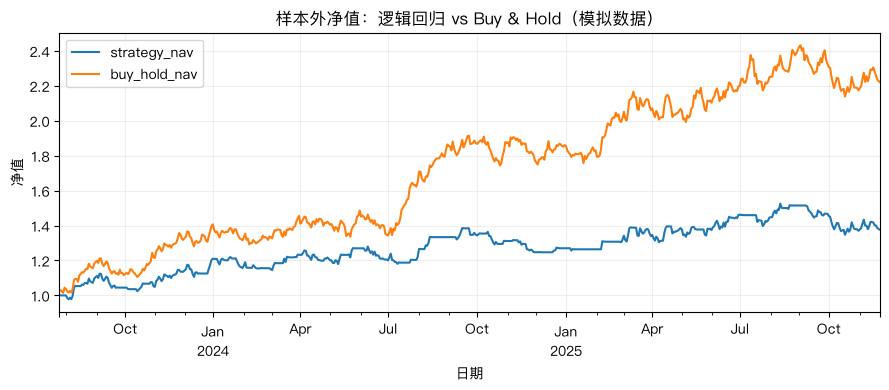

In [6]:
# 把样本外预测向后移动一日，并与 Buy & Hold 比较。
evaluation["asset_return"] = frame.loc[evaluation.index, "return_1d"]
evaluation["position"] = evaluation["prediction"].shift(1).fillna(0)
evaluation["turnover"] = evaluation["position"].diff().abs().fillna(evaluation["position"].abs())
evaluation["strategy_return"] = (
    evaluation["position"] * evaluation["asset_return"] - 0.001 * evaluation["turnover"]
)
evaluation["strategy_nav"] = (1 + evaluation["strategy_return"]).cumprod()
evaluation["buy_hold_nav"] = (1 + evaluation["asset_return"]).cumprod()

axis = evaluation[["strategy_nav", "buy_hold_nav"]].plot(
    figsize=(9, 4), title="样本外净值：逻辑回归 vs Buy & Hold（模拟数据）"
)
axis.set(xlabel="日期", ylabel="净值")
axis.grid(alpha=0.2)
axis.figure.tight_layout()
axis.figure.savefig(OUTPUT_DIR / "50_oof_strategy.png", dpi=150)
plt.show()
assert evaluation["position"].iloc[1] == evaluation["prediction"].iloc[0]

## 方法边界与复用结论


- 轻微高于 50% 的准确率可能是噪声或类别不平衡，需跨时期、跨标的和置信区间验证。
- Accuracy 忽略涨跌幅大小；交易成本和少数大行情可能完全改变收益结果。
- 特征重要性不等于因果或稳定预测能力；所有变换都必须在每个训练折内部拟合。


本课代码验证的是方法和数据契约，不是未来收益。迁移到真实研究前，还需重新核对来源授权、复权、时区、可得时间、交易成本和样本外边界。